# Reelle und komplexe Schwingungen und ihre Zerlegungen

## 1. Zerlegung eines phasenverschobenen Sinussignals in Sinus- und Cosinus-Anteil

Zerlegung eines phasenverschobenen Sinussignals $u(t)=sin(2 \pi f (t-t_0))$ in einen geraden Anteil $u_g(t)$ und einen ungeraden Anteil $u_u(t)$. Eingestellt werden können 
Zeitversatz $t_0$ in Sekunden und Signalfrequenz $f$ in Hz.

Matplotlib is building the font cache; this may take a moment.


Output()

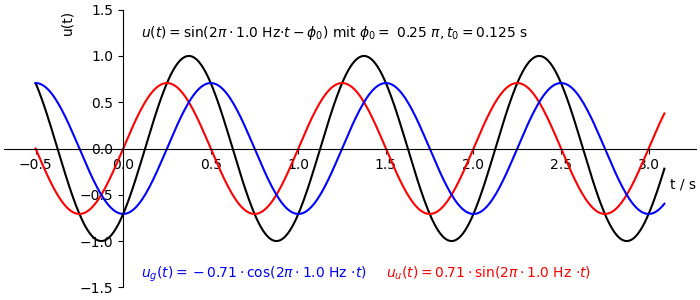

In [1]:
"""
Darstellung von Zerlegungen der Schwingungsfunktionen. 
Auch füf das Verständnis der komplexen Zahlenebene an sich/Drehwinkel verwendbar.

(c) Benno Dömer | HS Pforzheim 2023 

"""
import platform
if platform.system() == "Emscripten": # running in JupyterLite
    %pip install -r runtime-requirements.txt

# 'widget' für interaktive Plots
%matplotlib widget 

# Import so, dass möglichst viele Funktionen "wie in Matlab" zur Verfügung stehen:
from numpy import (pi, log10, exp, sqrt, sin, cos, tan, angle, arange, linspace, zeros, ones) # numpy für's Rechnen, bei Bedarf anpassen
import matplotlib.pyplot as plt
from matplotlib.pyplot import (figure, plot, stem, legend, text,  
                               grid, xlabel, ylabel, subplot, title, clf, cla, xlim, ylim, xticks, yticks) # matpotlib für's  Plotten, bei Bedarf anpassen
import ipywidgets as widgets # interaktive Controls wie Slider, Dropdowns etc.

def myplotstyle(ax): # Hilfsfunktion, hübscht den Plot etwas auf
    ax.spines['right'].set_color('none')
    ax.spines['top'].set_color('none')
    ax.xaxis.set_ticks_position('bottom')
    ax.spines['bottom'].set_position(('data',0))
    ax.yaxis.set_ticks_position('left')
    ax.spines['left'].set_position(('data',0))

fig3, ax3= plt.subplots(figsize=(7, 3), dpi=100, layout='constrained',num='Zerlegung eines Sinussignals')

def plotsincos(f,t0): # diese Funktion wird aufgerufen, wenn Slider bewegt werden (und initial einmal)
    plt.figure(fig3)
    ax3.clear()
    t = arange(-0.5,3.1,0.01)
    phi = 2*pi*f*t0
    ax3.plot(t,sin(2*pi*f*(t-t0)),'k',t,sin(2*pi*f*t)*cos(phi),'r',t,-cos(2*pi*f*t)*sin(phi),'b')
    #ax3.text(0.1,1.05,'$\^{u}_g=$'+ f'{sin(phi):.2f}, ' + '$\^{u}_u=$'+ f'{cos(phi):.2f}, $\phi=${phi:.2f}')
    ax3.text(0.1,1.2,f'$u(t)=\\sin(2\\pi\\cdot${f:.1f} Hz$\\cdot t -\\phi_0)$ mit $\\phi_0=$ {phi/pi:.2f} $\\pi, t_0 = {t0:.3f}$ s')
    ax3.text(0.1,-1.4,f'$u_g(t)={-sin(phi):.2f}\\cdot\\cos(2\\pi\\cdot${f:.1f} Hz $\\cdot t$)',c='b')
    ax3.text(1.5,-1.4,f'$u_u(t)={cos(phi):.2f}\\cdot\\sin(2\\pi\\cdot${f:.1f} Hz $\\cdot t$)',c='r')
    ax3.set_xlabel('t / s',loc='right')
    ax3.set_ylabel('u(t)',loc='top')
    #ax3.legend(['$u(t)$','$u_u(t)$','$u_g(t)$'],loc='upper right')
    ax3.set_ylim(-1.5,1.5)
    myplotstyle(ax3)
    #fig3.canvas.draw()

# Definition von Bedienelementen
fslider  = widgets.FloatSlider(min=0.5, max=5, step=0.1, value=1, continuous_update=True, description='$f$/Hz')
tslider  = widgets.FloatSlider(min=-0.5, max=0.5, step=0.005, value=0.125, continuous_update=True, description='$t_0$/s')
ui3 = widgets.HBox([tslider, fslider])
#Verknüpfen mit Callback
out3 = widgets.interactive_output(plotsincos, { 'f': fslider,'t0': tslider}) 
#Anzeigen
display(ui3,out3)
plt.show()

## 2. Komplexe Schwingung als Addition eines Sin- und Cos-Signals
Eine komplexe Schwingung $e^{j\omega t}$ kann in ein reeles Cosinussignal und ein imaginäres Sinussignal gleicher Frequenz zerlegt werden: $y(t)= e^{j\omega t} = cos(\omega t)+ j\cdot sin(\omega t)$. Gegeben sei hier $\omega=2\pi$/s (Schwingung mit $f=\frac{\omega}{2\pi}=1$ Hz), die Zeit $t$ ist in Sekunden einstellbar

FloatSlider(value=0.125, description='t/s', max=2.0, step=0.025)

Output()

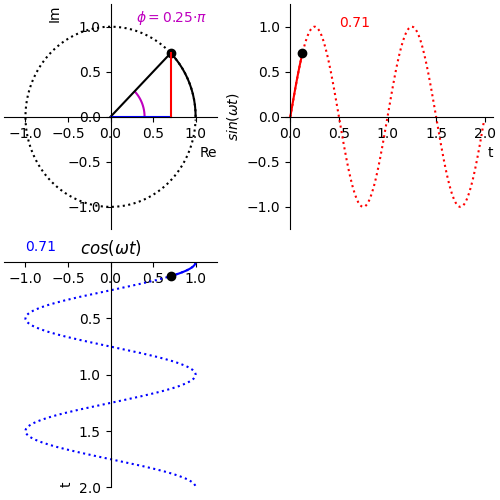

In [2]:

fig2 = figure(figsize=(5, 5), dpi=100, 
       layout='constrained',num='Fig1') # bei Bedarf anpassen, Achtung Tablet: Nicht über 7 Breite;

# hier in etwas anderem Handle-Stil, mehr "wie Matlab" mit figure, subplot etc.
def plotdata(t):
    figure('Fig1')

    ymax = 1.25
    omega = 2 * pi * 1 # f=1
    tx = arange(0,2,0.01); #Matlab: tx=0:0.01:2;
    tc = arange(0,t,0.01); #Matlab: tx=0:0.01:t;
    
    ax = subplot(2,2,3)
    cla()#matplotlib löscht den Plot nicht, "hold on"-Verhalten => explizit löschen 
    #plot(cos(tx*omega),tx,':b',cos(tc*omega),tc,'b',cos(t*omega),t,'ok') # Cos-Projektion oben
    plot(cos(tx*omega),tx,':b',cos(tc*omega),tc,'b',cos(t*omega),t,'ok') # Cos-Projektion oben
    ax.text(-1,-.1,f'{cos(t*omega):.2f}',color='b')
    #xlabel(r'$cos(\omega t)$')
    title(r'$cos(\omega t)$')
    ylabel('t',loc='bottom')
    myplotstyle(ax)
    xlim(-ymax,ymax)
    ylim(2,0)
    yticks([0.5, 1, 1.5, 2])
    
    ax = subplot(2,2,2)
    cla()
    plot(tx,sin(tx*omega),':r',tc,sin(tc*omega),'r',t,sin(t*omega),'ok') # Sin-Projektion rechts
    ax.text(0.5,1,f'{sin(t*omega):.2f}',color='r')
    ylim(-ymax, ymax)
    ylabel(r'$sin(\omega t)$')
    xlabel('t',loc='right')
    myplotstyle(ax)

    ax = subplot(2,2,1)
    cla()
    phi = t*2 # Winkel
    plot(cos(tx*pi),sin(tx*pi),':k',cos(tc*2*pi),sin(tc*2*pi),'k')
    plot(0.4*cos(tc*2*pi),0.4*sin(tc*2*pi),'m') # einen Kreis malen
    xlabel('Re',loc='right')
    ylabel('Im',loc='top')
    plot([0,cos(omega*t)],[0,sin(omega*t)],'-k',cos(omega*t),sin(omega*t),'ok',
        [0,cos(t*2*pi)],[0,0],'b',[cos(t*2*pi),cos(t*2*pi)],[0,sin(t*2*pi)],'r')
    #    [0,cos(omega*t)],[0,-sin(omega*t)],'--k',cos(omega*t),-sin(omega*t),'ok') # Zeiger zeichnen
    ax.text(0.3,1.05,r'$\phi=$'+f'{phi:.2f}'+r'$\cdot \pi$',color='m')
    xlim(-ymax,ymax)
    ylim(-ymax,ymax)
    
    myplotstyle(ax)
    #fig2.canvas.draw()
    
# Interaktion: 
# Definition von Controls: 
tslider1  = widgets.FloatSlider(min=0, max=2, step=0.025, value=0.125, continuous_update=True, description='t/s')

#Verknüpfen mit Callback
out1 = widgets.interactive_output(plotdata, { 't': tslider1}) 
#Anzeigen
display(tslider1,out1)
plt.show()


## 3. Sin und Cos als zwei gegenläufige komplexe Schwingungen
Reelle Sinus- und Cosinussignale lassen sich als Überlagerung zweier gegenläufiger komplexer Schwingungen darstellen: $cos(\omega t)=\frac{1}{2}(e^{j\omega t}+e^{-j\omega t})$ und $sin(\omega t)=\frac{1}{2j}(e^{j\omega t}-e^{-j\omega t})$. Gegeben sei wieder $\omega=2\pi$/s (Schwingung mit 1 Hz),  $t$ ist in Sekunden einstellbar

Der durchgehende schwarze Zeiger zeigt $e^{j\omega t}$, der gestrichelte $e^{-j\omega t}$. Das blaue Kästchen markiert $e^{j\omega t}+e^{-j\omega t}$, das rote Kästchen $e^{j\omega t}-e^{-j\omega t}$.

FloatSlider(value=0.0, description='t/s', max=2.0, step=0.05)

Output()

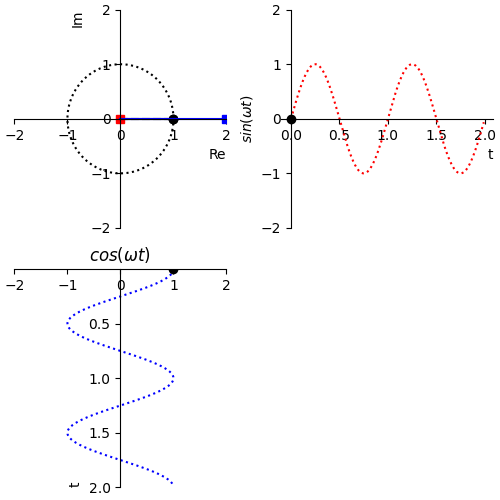

In [6]:
fig1 = figure(figsize=(5, 5), dpi=100, 
       layout='constrained',num='Fig2') # bei Bedarf anpassen, Achtung Tablet: Nicht über 7 Breite; Titel hinter "num", hier Leerzeichen

# Plotbefehle werden in eine Funktion verpackt, die dann bei Interaktionen aufgerufen wird. Hier ist die Kernfunktionalität
# In Python wird statt mit Klammern oder Schlüsselwörtern wie "end" mit Einrückungen gearbeitet
def plotdata2(t):
    figure('Fig2')
    f=1
    omega = 2 * pi * f
    tx = arange(0,2,0.01); #Matlab: tx=0:0.01:2;
    tc = arange(0,t,0.01); #Matlab: tx=0:0.01:t;
    
    ax = subplot(2,2,1)
    cla()
    plot(cos(tx*pi),sin(tx*pi),':k',cos(tc*2*pi),sin(tc*2*pi),'k') # einen Kreis malen
    xlabel('Re',loc='right')
    ylabel('Im',loc='top')
    plot([0,cos(omega*t)],[0,sin(omega*t)],'-k',cos(omega*t),sin(omega*t),'ok',
        [0,cos(omega*t)],[0,-sin(omega*t)],'--k',cos(omega*t),-sin(omega*t),'ok',
        2*cos(omega*t),0,'sb',0,2*sin(omega*t),'sr',
        [2*cos(omega*t),0],[0,0],'b',[0,0],[0,2*sin(omega*t)],'r') # Zeiger zeichnen
    xlim(-2,2)
    ylim(-2,2)
    
    myplotstyle(ax)
    #fig1.canvas.draw()
    
    ax = subplot(2,2,2)
    cla()
    plot(tx,sin(tx*omega),':r',tc,sin(tc*omega),'r',t,sin(t*omega),'ok') # Sin-Projektion rechts
    ylim(-2, 2)
    ylabel(r'$sin(\omega t)$')
    xlabel('t',loc='right')
    subplot(2,2,3)
    myplotstyle(ax)
    xlim(0,2)
    ylim(-2,2)
    

    ax = subplot(2,2,3)
    cla()#matplotlib löscht den Plot nicht, "hold on"-Verhalten => explizit löschen 
    plot(cos(tx*omega),tx,':b',cos(tc*omega),tc,'b',cos(t*omega),t,'ok') # Cos-Projektion oben
    title(r'$cos(\omega t)$')
    ylabel('t',loc='bottom')
    myplotstyle(ax)
    xlim(-2,2)
    ylim(2,0)
    yticks([0.5, 1, 1.5, 2])
    
    
# Interaktion: 
# Definition von Controls: 
tslider2  = widgets.FloatSlider(min=0, max=2, step=0.05, value=0, continuous_update=True, description='t/s')

#Verknüpfen mit Callback
out = widgets.interactive_output(plotdata2, { 't': tslider2}) 
#Anzeigen
display(tslider2,out)
plt.show()
